# Shallow water: frames come home while the steps run

> A mound of water collapses into waves. Each replay of one graph advances the water a few steps and, at the same
> time, copies the previous frame to host memory. Eagle orders everything from the arrays each node touches, and the only wait inside a replay is the one you write.

**Time:** ~6 min · **Runs on:** CPU (a GPU is picked up automatically and runs a larger pond) · **You need:** eagle, hawk, NumPy and matplotlib; read first: {doc}`../graph_across_devices`

The step is the finite-volume shallow-water step of [hawk's fluids page](https://amasat01.github.io/hawk/content/vocabulary/10_fluids.html),
a Rusanov flux on a periodic grid. The kernel is explained there and repeated below unchanged. Units: `g` = 1, a cell is
1 wide, still water is 1 deep. For the scheme's stability and energy, see that page.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import gpu_available, plot_style, to_numpy, xp_for

In [3]:
import numpy as np

DEVICE = "gpu" if gpu_available() else "cpu"
xp = xp_for(DEVICE)
N = 256 if DEVICE == "gpu" else 64
LAM, G = 0.35, 1.0
print("running on", DEVICE, f"with a {N} x {N} pond")

running on cpu with a 64 x 64 pond


## The kernel

One step with three outputs (depth and the two momenta). It is hawk's kernel, with the width as a parameter.

In [4]:
import eagle
import hawk
import hawk.math as m
from hawk import Grid, Mutable, Param, Scalar


def push(h, p, g):
    return p * p / h + 0.5 * g * h * h


def speed(h, p, g):
    return m.abs(p / h) + m.sqrt(g * h)


def rusanov(f_left, f_right, u_left, u_right, a):
    return 0.5 * (f_left + f_right) - 0.5 * a * (u_right - u_left)


def swe_kernel(width):
    @hawk.kernel
    def swe_step(lane: Grid["row", "col":width], h: Scalar, hu: Scalar, hv: Scalar, lam: Param, g: Param,
                 h_new: Mutable[Scalar], hu_new: Mutable[Scalar], hv_new: Mutable[Scalar]):
        i, j = lane.row, lane.col
        if i == 0:
            n = i + (width - 1)
        else:
            n = i - 1
        if i == width - 1:
            s = i - (width - 1)
        else:
            s = i + 1
        if j == 0:
            w = j + (width - 1)
        else:
            w = j - 1
        if j == width - 1:
            e = j - (width - 1)
        else:
            e = j + 1
        he, hue, hve = h.at(row=i, col=e), hu.at(row=i, col=e), hv.at(row=i, col=e)
        hw, huw, hvw = h.at(row=i, col=w), hu.at(row=i, col=w), hv.at(row=i, col=w)
        hn, hun, hvn = h.at(row=n, col=j), hu.at(row=n, col=j), hv.at(row=n, col=j)
        hs, hus, hvs = h.at(row=s, col=j), hu.at(row=s, col=j), hv.at(row=s, col=j)
        a_e = m.max(speed(h, hu, g), speed(he, hue, g))
        a_w = m.max(speed(hw, huw, g), speed(h, hu, g))
        a_s = m.max(speed(h, hv, g), speed(hs, hvs, g))
        a_n = m.max(speed(hn, hvn, g), speed(h, hv, g))
        h_new = h - lam * (rusanov(hu, hue, h, he, a_e) - rusanov(huw, hu, hw, h, a_w)
                           + rusanov(hv, hvs, h, hs, a_s) - rusanov(hvn, hv, hn, h, a_n))
        hu_new = hu - lam * (rusanov(push(h, hu, g), push(he, hue, g), hu, hue, a_e)
                             - rusanov(push(hw, huw, g), push(h, hu, g), huw, hu, a_w)
                             + rusanov(hu * hv / h, hus * hvs / hs, hu, hus, a_s)
                             - rusanov(hun * hvn / hn, hu * hv / h, hun, hu, a_n))
        hv_new = hv - lam * (rusanov(hu * hv / h, hue * hve / he, hv, hve, a_e)
                             - rusanov(huw * hvw / hw, hu * hv / h, hvw, hv, a_w)
                             + rusanov(push(h, hv, g), push(hs, hvs, g), hv, hvs, a_s)
                             - rusanov(push(hn, hvn, g), push(h, hv, g), hvn, hv, a_n))
    return swe_step


def mound(width):
    """Still water of depth 1 with a smooth raised mound in the middle."""
    y, x = np.mgrid[0:width, 0:width]
    h = 1.0 + 0.4 * np.exp(-((x - width / 2) ** 2 + (y - width / 2) ** 2) / (width / 6) ** 2)
    return h, np.zeros_like(h), np.zeros_like(h)


swe = swe_kernel(N)


def step(src, dst):
    """One step from the arrays `src` (depth, two momenta) into `dst`."""
    swe(h=src[0], hu=src[1], hv=src[2], lam=LAM, g=G, h_new=dst[0], hu_new=dst[1], hv_new=dst[2])

## The graph: a frame leaves while the steps run

A replay does `STEPS` steps. The state lives in `a`; `b` and `c` are scratch of the same shape. Two branches run
together:

- one copies the depth in `a` to a host array and hands it to a host function that keeps it;
- the other steps `a -> b -> c -> b ...`. Those steps only read `a` at the start, so they do not have to wait for the copy.

Only the last step writes `a`, so it waits for the copy to finish (`w.wait(h_frame)` names the array the copy wrote).
That is the double buffer. Frame `k` is the depth at the start of replay `k`.

The host array is page-locked on a GPU (`eagle.pinned`; your decision, not eagle's) and an ordinary array on the CPU.
`eagle.opaque(fn, reads=..., writes=...)` makes your own Python function a graph node; `reads=` and `writes=` tell eagle
which arrays it touches, so it can order it.

In [5]:
STEPS = 4
assert STEPS >= 2, "a replay needs a step that only reads `a` and a last one that overwrites it"


def host_array(shape):
    """Page-locked on a GPU; an ordinary array on the CPU."""
    return eagle.pinned(shape) if DEVICE == "gpu" else np.zeros(shape)


class Frames:
    """A host function: keeps a copy of each frame the graph hands over."""

    def __init__(self, field):
        self.field, self.kept = field, []

    def __call__(self):
        self.kept.append(self.field.copy())


def make_advance(frames):
    @eagle.Graph.builder
    def advance(a, b, c, h_frame):
        g = eagle.Graph()
        with g.parallel() as p:
            with p.branch():
                eagle.copy(a[0], into=h_frame)                       # device -> host
                eagle.opaque(frames, reads=(h_frame,), writes=(), name="keep")
            with p.branch() as w:
                step(a, b)                                           # reads `a`, writes `b`
                last = b
                for _ in range(STEPS - 2):
                    nxt = c if last is b else b
                    step(last, nxt)
                    last = nxt
                w.wait(h_frame)                                      # the step that overwrites `a` waits for the copy
                step(last, a)
        return g
    return advance


def fresh(width):
    h, hu, hv = mound(width)
    a = [xp.array(f) for f in (h, hu, hv)]
    b = [xp.zeros((width, width)) for _ in range(3)]
    c = [xp.zeros((width, width)) for _ in range(3)]
    return a, b, c


a, b, c = fresh(N)
h_frame = host_array((N, N))
frames = Frames(h_frame)
g = make_advance(frames)(a, b, c, h_frame)
print("backend:", g.backend, "| nodes:", g.node_labels())

backend: cpu | nodes: ['copy', 'keep', 'swe_step', 'swe_step#2', 'swe_step#3', 'wait', 'swe_step#4']


## The schedule, drawn from the graph

This is the order the graph allows, taken from its nodes and its edges: each node takes one time slot, and a node starts
as soon as every node it depends on has finished. It is a picture of the structure, not a measurement. The copy and
the first steps start together; the host function follows the copy; the last step waits for the copy.


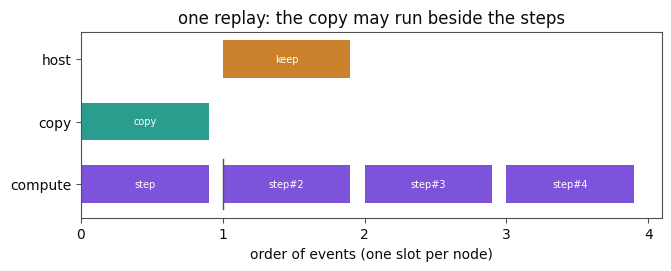
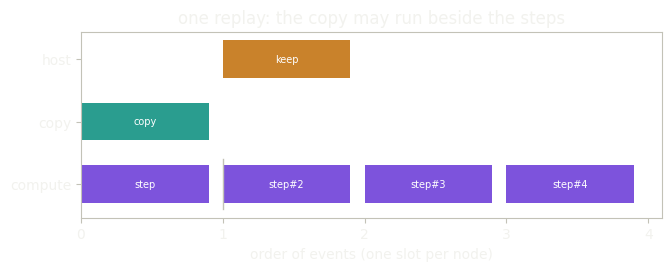

In [6]:
import matplotlib.pyplot as plt
from themed_figure import show

LANES = ("compute", "copy", "host")
COLOURS = {"compute": "#7d53dc", "copy": "#2a9d8f", "host": "#c9822b"}


def lane_of(label):
    if label.startswith("copy"):
        return "copy"
    if label == "keep":
        return "host"
    return "compute"


def slots(graph):
    """Each node's start slot: one past the latest node it depends on."""
    after = {}
    for e in graph.edges():
        after.setdefault(e.dst, set()).add(e.src)
    start = {}
    for i in range(graph.num_nodes()):          # edges point forward in add order
        start[i] = 1 + max((start[j] for j in after.get(i, ())), default=-1)
    return start


plot_style()
labels = g.node_labels()
start = slots(g)
fig, ax = plt.subplots(figsize=(6.6, 2.6), constrained_layout=True)
for i, label in enumerate(labels):
    lane = lane_of(label)
    if label == "wait":
        ax.plot([start[i]] * 2, [LANES.index(lane) - 0.4, LANES.index(lane) + 0.4], color="#898781", lw=1)
        continue
    ax.barh(LANES.index(lane), 0.9, left=start[i], color=COLOURS[lane], height=0.6)
    ax.text(start[i] + 0.45, LANES.index(lane), label.replace("swe_step", "step"), ha="center", va="center", fontsize=7, color="white")
ax.set_yticks(range(len(LANES)), LANES)
ax.set_xticks(range(max(start.values()) + 2))
ax.set_xlabel("order of events (one slot per node)")
ax.set_title("one replay: the copy may run beside the steps")
show()

## Run it, and check it twice

`g.launch(FRAMES)` replays the graph `FRAMES` times with no host involvement in between. Then three checks:

- water is neither made nor lost: the total depth in every kept frame equals the first, to rounding;
- a round mound on a square grid stays mirror-symmetric;
- the frames equal those of the same builder run with NumPy arrays only, so that every node runs on the host. The two
  agree to rounding. (On a CPU the two runs are the same computation, so the agreement is exact there.)

In [7]:
FRAMES = 40
g.launch(FRAMES)
kept = np.array(frames.kept)
TOL = 1e-12
volume = kept.sum(axis=(1, 2))
drift = np.abs(volume / volume[0] - 1.0).max()
assert drift < TOL, drift
print(f"{len(kept)} frames kept on the host; total depth {volume[0]:.4f}, largest relative change {drift:.1e} < {TOL:g}")
asym = np.abs(kept[-1] - kept[-1].T).max()
assert asym < TOL, asym
print(f"symmetry: largest difference between the depth and its mirror image {asym:.1e} < {TOL:g}")

# the same builder run with NumPy arrays only: every node runs on the host
ha, hb, hc = ([to_numpy(f) for f in s] for s in fresh(N))
host_frame = np.zeros((N, N))
host_only = Frames(host_frame)
gt = make_advance(host_only)(ha, hb, hc, host_frame)
gt.launch(FRAMES)
diff = np.abs(np.array(host_only.kept) - kept).max()
assert diff < TOL, diff
print(f"against the NumPy-only run: largest difference {diff:.1e} < {TOL:g}")

40 frames kept on the host; total depth 4238.9709, largest relative change 2.2e-16 < 1e-12
symmetry: largest difference between the depth and its mirror image 4.4e-16 < 1e-12
against the NumPy-only run: largest difference 0.0e+00 < 1e-12



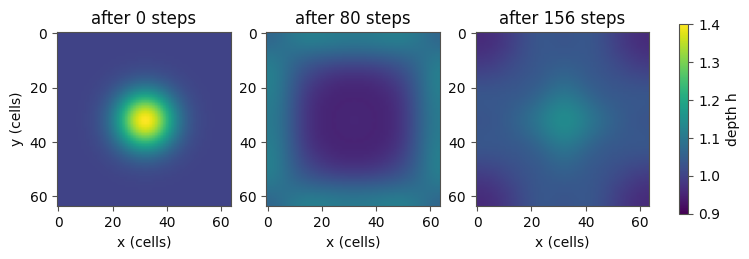
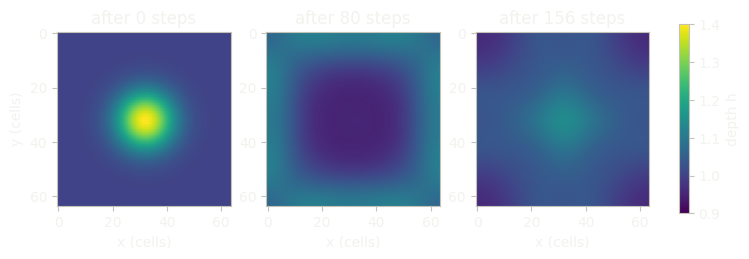

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.6), constrained_layout=True)
for ax, k in zip(axes, (0, FRAMES // 2, FRAMES - 1)):
    im = ax.imshow(kept[k], vmin=0.9, vmax=1.4, cmap="viridis")
    ax.set_title(f"after {k * STEPS} steps")
    ax.set_xlabel("x (cells)")
axes[0].set_ylabel("y (cells)")
fig.colorbar(im, ax=axes, shrink=0.8, label="depth h")
show()

## What just happened

- One graph held GPU steps, a device-to-host copy and a host function. Frames came home through a page-locked array while
  the next steps ran in the other branch.
- The only wait inside a replay is the one you wrote: the step that overwrites `a` waits for the copy that reads it.
- The same builder with NumPy arrays only gave the same frames, so that run is a check you can always make.
- The graph makes the overlap allowed; whether it happened on your device is something you can look at. Run the script
  under `nsys profile python run.py` (Nsight Systems, as in {doc}`08_profile_your_run`) and look at the timeline: the
  copy and the step kernels appear on different streams, and if they overlap in time the copy was hidden. This page
  makes no timing claim. The cost of a host node and the rules are in {doc}`../graph_across_devices`.

## Next

- {doc}`22_heat_energy_check`: an energy check copied home every few steps.
- {doc}`../graph_across_devices`: the rules for host nodes and copies.